# FWI Fundamentals: Python Exercises with Devito

Companion notebook to the comprehensive examination report *Full Waveform Inversion: Fundamentals, Mathematical Framework, Types and Applications, with Python Exercises in Devito* (Yudha Adi Putra, KFUPM, 2026).

**Tools.** [Devito](https://github.com/devitocodes/devito) v4.8.23 (finite-difference code generation, Louboutin et al., 2019; Luporini et al., 2020), its seismic utilities in `examples/seismic` (`SeismicModel`, `AcquisitionGeometry`, `AcousticWaveSolver`), NumPy, SciPy (`scipy.optimize`, `scipy.ndimage`) and Matplotlib.

**Sources.** The exercises follow and extend the official Devito tutorials in the repository `devitocodes/devito` (tag v4.8.23):

| Exercise | Based on |
|---|---|
| 1 Forward modeling | `examples/seismic/tutorials/01_modelling.ipynb`; Louboutin et al. (2017), TLE *FWI Part 1* |
| 2 Numerical accuracy | Devito `space_order` / `critical_dt` (`examples/seismic/model.py`); `07.1_dispersion_relation.ipynb` |
| 3 Gradient and Taylor test | `examples/seismic/tutorials/03_fwi.ipynb`; `tests/test_gradient.py::test_gradientFWI`; Louboutin et al. (2018), TLE *FWI Part 2* |
| 4 Multiscale FWI | `03_fwi.ipynb` extended with SciPy L-BFGS-B, as in Witte et al. (2018), TLE *FWI Part 3* |
| 5 Cycle skipping | Own experiment on the same set-up, after Bunks et al. (1995) |

**Model.** 2-D Marmousi P-wave velocity (Versteeg, 1994) from the repository `devitocodes/data` (`Simple2D/vp_marmousi_bi`), cropped to a 4.5 km × 1.8 km section and resampled to 25 m.

**Set-up.**
```
git clone --branch v4.8.23 https://github.com/devitocodes/devito.git
git clone https://github.com/devitocodes/data.git devito-data
pip install "devito[extras]" pytest
```
Set `DEVITO_REPO` and `DATA_PATH` below. Run time is about 30 minutes on a laptop (set `FAST = True` for a quicker run).

In [1]:
import os, sys, time, numpy as np, matplotlib.pyplot as plt
DEVITO_REPO = os.environ.get('DEVITO_REPO', './devito')        # path to the cloned devito repo
DATA_PATH   = os.environ.get('DATA_PATH', './devito-data')     # path to devitocodes/data
sys.path.insert(0, DEVITO_REPO)

import devito
from devito import configuration, Function, norm
configuration['log-level'] = 'ERROR'
from examples.seismic import SeismicModel, AcquisitionGeometry, Receiver, demo_model
from examples.seismic.acoustic import AcousticWaveSolver
from scipy.ndimage import gaussian_filter, zoom
from scipy.optimize import minimize
print('Devito', devito.__version__)

FAST = os.environ.get('FAST', '0') == '1'      # quicker, rougher run
FIG = 'figs'; os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.titleweight': 'bold'})
def save(name): plt.savefig(f'{FIG}/{name}.png', dpi=160, bbox_inches='tight')

Devito 4.8.23


In [2]:
# ---- Marmousi section (Devito arrays are indexed [x, z]; units: km/s, m, ms, kHz)
vm = np.fromfile(f'{DATA_PATH}/Simple2D/vp_marmousi_bi', dtype='float32').reshape(1601, 401)   # 7.5 m grid
vt = zoom(vm[600:1200, :240], 7.5/25, order=1).astype(np.float32)                              # 4.5 x 1.8 km, 25 m
dx, nbl, so = 25., 40, 8
water = vt <= 1.51                                   # water layer: known, never updated
nx, nz = vt.shape; Lx = (nx - 1) * dx
ext = [0, Lx/1000, (nz - 1)*dx/1000, 0]
DT = 2.3                                             # ms; stable up to ~5.6 km/s, so updated or scaled models never break the CFL limit
def make_model(v, grid=None):
    return SeismicModel(vp=v, origin=(0., 0.), spacing=(dx, dx), shape=v.shape, space_order=so, nbl=nbl, bcs='damp', grid=grid, dt=DT)
model = make_model(vt)
print(f'grid {nx} x {nz} (dx = {dx:.0f} m), vp {vt.min():.2f}-{vt.max():.2f} km/s, time step = {model.critical_dt:.2f} ms')

nrec, nshots = 181, (6 if FAST else 16)
rec_xy = np.zeros((nrec, 2)); rec_xy[:, 0] = np.linspace(0, Lx, nrec); rec_xy[:, 1] = 12.5
src_x = np.linspace(100, Lx - 100, nshots)
T_END = 3000.                                         # ms
def geometry(f0_hz, sx=Lx/2):
    return AcquisitionGeometry(model, rec_xy, np.array([[sx, 12.5]]), 0., T_END, f0=f0_hz/1000, src_type='Ricker')

grid 180 x 72 (dx = 25 m), vp 1.50-4.45 km/s, time step = 2.30 ms


---
## Exercise 1 — Forward modeling

**Goal.** Simulate seismic shots with Devito's acoustic solver, which discretizes
$\frac{1}{v^2}\partial_t^2 u - \nabla^2 u = s$ with second-order time and eighth-order space stencils (`space_order=8`) and a damping absorbing layer (`nbl=40` points).

**Tools.** `SeismicModel`, `AcquisitionGeometry` (Ricker source, 181 receivers at 12.5 m depth), `AcousticWaveSolver.forward(save=True)`.

**Task.** Plot the model, wavefield snapshots and the shot gather; identify direct, reflected and diving/refracted waves.

one shot: 0.9 s, 1306 time steps of 2.30 ms


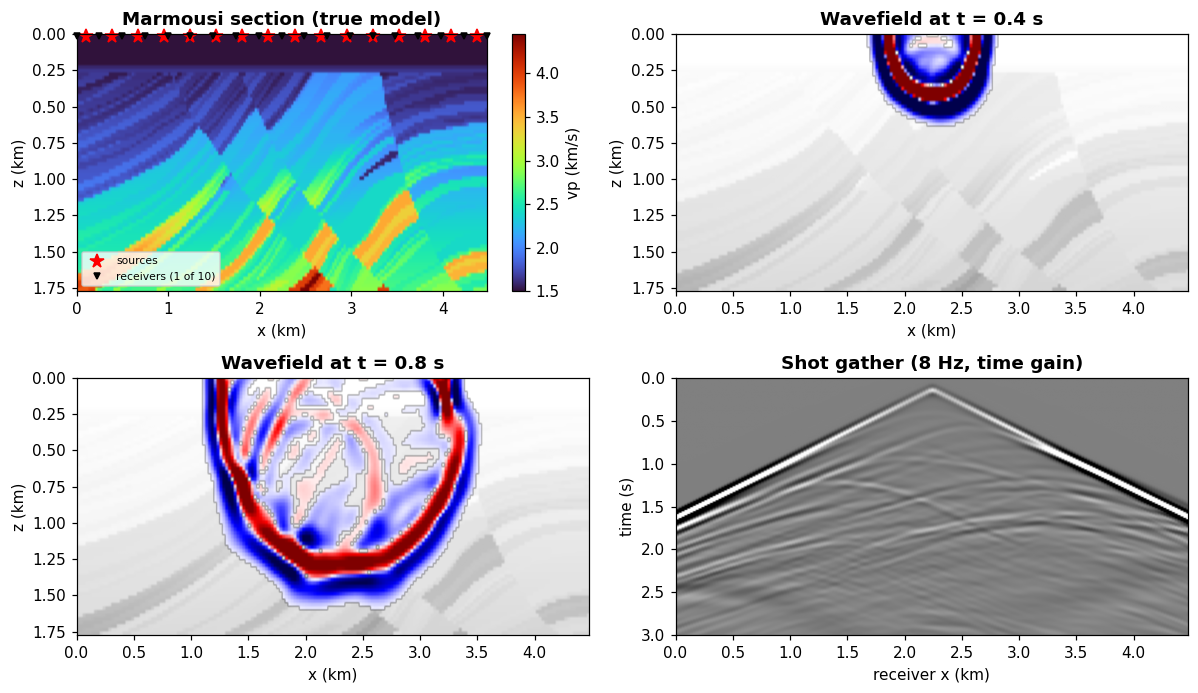

In [3]:
geo = geometry(8.0)
solver = AcousticWaveSolver(model, geo, space_order=so)
t0 = time.time(); d, u, _ = solver.forward(save=True); print(f'one shot: {time.time()-t0:.1f} s, {geo.nt} time steps of {geo.dt:.2f} ms')

fig = plt.figure(figsize=(11, 6.4))
a = fig.add_subplot(2, 2, 1)
im = a.imshow(vt.T, cmap='turbo', extent=ext, aspect='auto'); fig.colorbar(im, ax=a, label='vp (km/s)')
a.plot(src_x/1000, 0.0125*np.ones(nshots), 'r*', ms=9, clip_on=False, label='sources'); a.plot(rec_xy[::10, 0]/1000, rec_xy[::10, 1]/1000, 'kv', ms=4, clip_on=False, label='receivers (1 of 10)')
a.set_title('Marmousi section (true model)'); a.set_xlabel('x (km)'); a.set_ylabel('z (km)'); a.legend(fontsize=7, loc='lower left')
for a, tt in [(fig.add_subplot(2, 2, 2), 400.), (fig.add_subplot(2, 2, 3), 800.)]:
    it = int(tt / geo.dt); snap = np.asarray(u.data)[it, nbl:-nbl, nbl:-nbl]; c = np.percentile(np.abs(snap), 97)
    a.imshow(vt.T, cmap='gray_r', extent=ext, aspect='auto', alpha=0.35)
    a.imshow(np.ma.masked_where(np.abs(snap.T) < c/30, snap.T), cmap='seismic', vmin=-c, vmax=c, extent=ext, aspect='auto')
    a.set_title(f'Wavefield at t = {tt/1000:.1f} s'); a.set_xlabel('x (km)'); a.set_ylabel('z (km)')
a = fig.add_subplot(2, 2, 4)
g = np.asarray(d.data) * np.linspace(0, 1, geo.nt)[:, None]**1.5
c = np.percentile(np.abs(g), 98)
a.imshow(g, cmap='gray', vmin=-c, vmax=c, aspect='auto', extent=[0, Lx/1000, T_END/1000, 0])
a.set_title('Shot gather (8 Hz, time gain)'); a.set_xlabel('receiver x (km)'); a.set_ylabel('time (s)')
plt.tight_layout(); save('ex1_forward'); plt.show()

**Discussion.** The direct wave travels along the surface in the water layer; reflections from the dipping Marmousi layers form a dense set of curved events; at far offsets the first arrivals are diving/refracted waves that have travelled through the faster deep layers. The snapshots show the wavefront being distorted, reflected and diffracted by the faulted structure, which is exactly the information FWI tries to exploit.

---
## Exercise 2 — Numerical accuracy: time step and stencil order

**Goal.** See how Devito chooses a stable time step and how the spatial stencil order controls numerical dispersion.

**Tools.** `model.critical_dt` (CFL-limited time step, `examples/seismic/model.py`); the `space_order` argument of `SeismicModel` and `AcousticWaveSolver`.

**Task.** Record a 15 Hz pulse at 1.2 km offset in a homogeneous 1.5 km/s medium on a 15 m grid (about 3 points per minimum wavelength) with `space_order` = 2, 4 and 8, and compare with a fine-grid reference. All runs use the same small time step (0.5 ms), so the differences come from the spatial stencil only.

Marmousi: vmax = 4.45 km/s, dx = 25 m -> Devito critical dt = 2.915 ms (Courant number 0.519); we use dt = 2.3 ms so that models up to 5.6 km/s stay stable


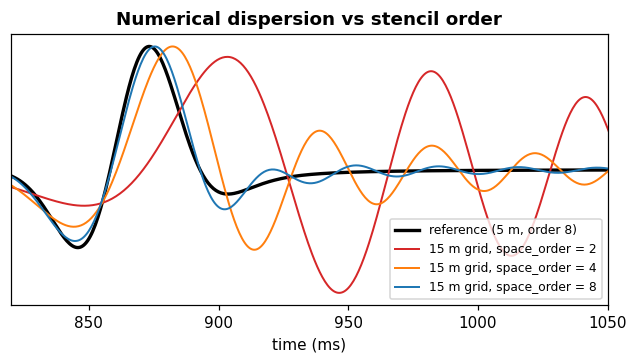

In [4]:
cfl_dt = SeismicModel(vp=vt, origin=(0., 0.), spacing=(dx, dx), shape=vt.shape, space_order=so, nbl=nbl, bcs='damp').critical_dt
print(f'Marmousi: vmax = {vt.max():.2f} km/s, dx = {dx:.0f} m -> Devito critical dt = {cfl_dt:.3f} ms (Courant number {vt.max()*cfl_dt/dx:.3f}); '
      f'we use dt = {DT} ms so that models up to {cfl_dt*vt.max()/DT:.1f} km/s stay stable')
def trace(h, order, dt=0.5):                      # same small dt for all runs -> only spatial dispersion differs
    n = int(1800/h) + 1
    m = SeismicModel(vp=np.full((n, n), 1.5, dtype=np.float32), origin=(0., 0.), spacing=(h, h), shape=(n, n), space_order=order, nbl=40, bcs='damp', dt=dt)
    g = AcquisitionGeometry(m, np.array([[1500., 900.]]), np.array([[300., 900.]]), 0., 1100., f0=0.015, src_type='Ricker')
    r, _, _ = AcousticWaveSolver(m, g, space_order=order).forward()
    return g.time_axis.time_values, np.asarray(r.data)[:, 0]
plt.figure(figsize=(7, 3.2))
tref, dref = trace(5., 8); plt.plot(tref, dref/np.abs(dref).max(), 'k', lw=2.2, label='reference (5 m, order 8)')
for order, col in [(2, 'C3'), (4, 'C1'), (8, 'C0')]:
    tt, dd = trace(15., order); plt.plot(tt, dd/np.abs(dd).max(), col, lw=1.3, label=f'15 m grid, space_order = {order}')
plt.xlim(820, 1050); plt.xlabel('time (ms)'); plt.yticks([]); plt.legend(fontsize=8)
plt.title('Numerical dispersion vs stencil order'); save('ex2_dispersion'); plt.show()

**Discussion.** Devito computes the largest stable time step from the CFL condition automatically. On a coarse grid the second-order stencil delays the pulse and adds a ringing tail (dispersion); higher-order stencils (4, 8) stay close to the reference. High-order stencils therefore allow coarser grids, which is why FWI codes, including Devito's examples, typically use `space_order` 8 or higher. Any dispersion left in the modeling would be inverted into false structure.

---
## Exercise 3 — The FWI gradient and the Taylor test

**Goal.** Compute the FWI gradient with the adjoint-state method and verify it, exactly as in Devito's FWI tutorial and gradient test.

**Tools.** `demo_model('circle-isotropic')` (a 3.0 km/s circle in a 2.5 km/s background, as in `03_fwi.ipynb`), `solver.forward(save=True)` for the forward wavefield, `solver.jacobian_adjoint(residual, u0)` for the back-propagated residual and the gradient with respect to squared slowness $m = 1/v^2$:
$$\frac{\partial J}{\partial m}(\mathbf{x}) = \sum_s \int_0^T \lambda(\mathbf{x}, t)\,\partial_t^2 u(\mathbf{x}, t)\,dt \quad\text{(sign convention of Devito)} .$$

**Task.** (a) Compute and plot the gradient for 9 shots (cross-well geometry, as in the tutorial). (b) Taylor test from `tests/test_gradient.py`: the error $|J(m_0 + h\,\delta m) - J(m_0) - h\,\langle g, \delta m\rangle|$ must decrease as $h^2$.

misfit J0 = 39294.2


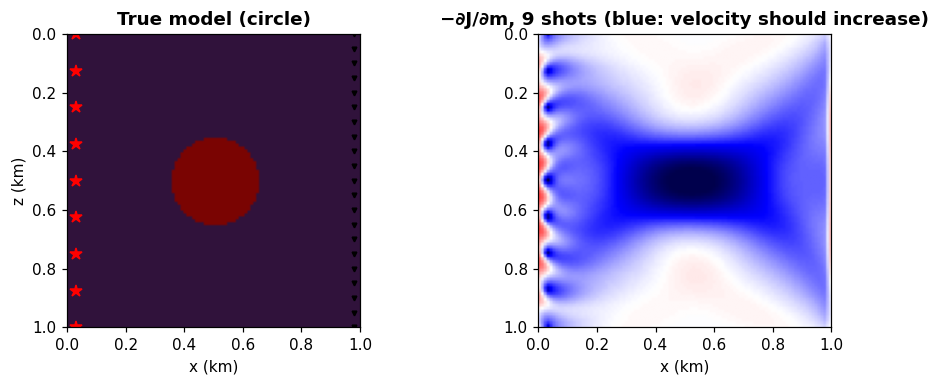

In [5]:
cshape, csp = (101, 101), (10., 10.)
cmodel  = demo_model('circle-isotropic', vp_circle=3.0, vp_background=2.5, origin=(0., 0.), shape=cshape, spacing=csp, nbl=40)
cmodel0 = demo_model('circle-isotropic', vp_circle=2.5, vp_background=2.5, origin=(0., 0.), shape=cshape, spacing=csp, nbl=40, grid=cmodel.grid)
crec = np.zeros((101, 2)); crec[:, 1] = np.linspace(0, 1000, 101); crec[:, 0] = 980.
cgeo = AcquisitionGeometry(cmodel, crec, np.array([[20., 500.]]), 0., 1000., f0=0.010, src_type='Ricker')
csolver = AcousticWaveSolver(cmodel, cgeo, space_order=4)
csrc = np.zeros((9, 2)); csrc[:, 0] = 30.; csrc[:, 1] = np.linspace(0., 1000., 9)
def circle_misfit_grad(vp_in, with_grad=True):
    grad = Function(name='grad', grid=cmodel.grid)
    res = Receiver(name='res', grid=cmodel.grid, time_range=cgeo.time_axis, coordinates=cgeo.rec_positions)
    J = 0.
    for s in csrc:
        cgeo.src_positions[0, :] = s
        dobs, _, _ = csolver.forward(vp=cmodel.vp)
        dsyn, u0, _ = csolver.forward(vp=vp_in, save=with_grad)
        res.data[:] = np.asarray(dsyn.data) - np.asarray(dobs.data)
        J += .5 * norm(res)**2
        if with_grad: csolver.jacobian_adjoint(res, u0, vp=vp_in, grad=grad)
    return J, grad
J0, g = circle_misfit_grad(cmodel0.vp)
print(f'misfit J0 = {J0:.1f}')
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].imshow(np.asarray(cmodel.vp.data)[40:-40, 40:-40].T, cmap='turbo', extent=[0, 1, 1, 0]); ax[0].set_title('True model (circle)')
ax[0].plot(csrc[:, 0]/1000, csrc[:, 1]/1000, 'r*', ms=8); ax[0].plot(crec[::5, 0]/1000, crec[::5, 1]/1000, 'kv', ms=3)
gi = np.asarray(g.data)[40:-40, 40:-40].T; c = np.percentile(np.abs(gi), 99)
ax[1].imshow(-gi, cmap='seismic', vmin=-c, vmax=c, extent=[0, 1, 1, 0]); ax[1].set_title('−∂J/∂m, 9 shots (blue: velocity should increase)')
for a in ax: a.set_xlabel('x (km)')
ax[0].set_ylabel('z (km)'); plt.tight_layout(); save('ex3_gradient'); plt.show()

h: [0.5, 0.25, 0.125, 0.0625, 0.03125, 0.015625, 0.0078125]
first-order errors : [27523.297 15189.453  7859.03   3983.957  2004.918  1005.414   503.18 ]
second-order errors: [5055.455  1099.9229  285.6587   88.387    31.254    12.6719    5.8633]


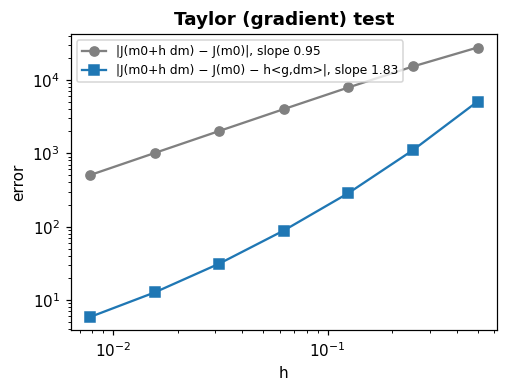

first-order slope = 0.95 (expect 1), second-order slope = 1.83 (expect 2)


In [6]:
# Taylor test (after tests/test_gradient.py::test_gradientFWI): perturb along dm = m_true - m0
v0 = np.array(cmodel0.vp.data); v = np.array(cmodel.vp.data)
dm = v**(-2) - v0**(-2)
G = np.dot(np.asarray(g.data).reshape(-1), dm.reshape(-1))
H = [0.5, 0.25, 0.125, 0.0625, 0.03125, 0.015625, 0.0078125]
vloc = Function(name='vloc', grid=cmodel.grid, space_order=4)
e1, e2 = [], []
for h in H:
    vh = np.sqrt(v0**2 * v**2 / ((1 - h) * v**2 + h * v0**2))             # m0 + h*dm, written as velocity
    pad = [((a - b) // 2,) * 2 for a, b in zip(vloc.data_with_halo.shape, vh.shape)]
    vloc.data_with_halo[:] = np.pad(vh, pad, mode='edge')                 # fill the halo too (zero velocity there gives NaN)
    Jh, _ = circle_misfit_grad(vloc, with_grad=False)
    e1.append(abs(Jh - J0)); e2.append(abs(Jh - J0 - h * G))
p1, p2 = np.polyfit(np.log(H[:5]), np.log(e1[:5]), 1)[0], np.polyfit(np.log(H[:5]), np.log(e2[:5]), 1)[0]   # smallest h are limited by float32 round-off
print('h:', H); print('first-order errors :', np.round(e1, 3)); print('second-order errors:', np.round(e2, 4))
plt.figure(figsize=(5, 3.5))
plt.loglog(H, e1, 'o-', color='gray', label=f'|J(m0+h dm) − J(m0)|, slope {p1:.2f}')
plt.loglog(H, e2, 's-', color='C0', label=f'|J(m0+h dm) − J(m0) − h<g,dm>|, slope {p2:.2f}')
plt.xlabel('h'); plt.ylabel('error'); plt.legend(fontsize=8); plt.title('Taylor (gradient) test')
save('ex3_taylor'); plt.show()
print(f'first-order slope = {p1:.2f} (expect 1), second-order slope = {p2:.2f} (expect 2)')

**Discussion.** The gradient is concentrated on the circular anomaly but smeared along the wave paths between the two "wells", the typical finite-frequency footprint of a single-iteration update. The Taylor test gives slopes of about 1 and 2, so the adjoint gradient is correct. The gradient is the correlation of the forward wavefield with the back-propagated residual: the same imaging condition as reverse-time migration.

---
## Exercise 4 — Multiscale FWI on the Marmousi section

**Goal.** Run a complete FWI: misfit and gradient from Devito, optimization with SciPy's L-BFGS-B, velocity bounds, an illumination preconditioner and a low-to-high frequency strategy.

**Tools.** Devito `AcousticWaveSolver` (`forward`, `jacobian_adjoint`), `scipy.optimize.minimize(method='L-BFGS-B')`, `scipy.ndimage.gaussian_filter` (starting model).

**Set-up.** 16 shots at 12.5 m depth, 181 receivers, 3 s recording; starting model = true model smoothed with a Gaussian of σ = 150 m (a stand-in for tomography), water layer kept; bands: Ricker 3 → 5 → 8 Hz; bounds 1.5–4.7 km/s.

In [7]:
model0 = make_model(np.where(water, 1.5, gaussian_filter(vt, 6)).astype(np.float32), grid=model.grid)
upd = ~water                                            # cells that are updated
def rel_err(v): return np.linalg.norm((v - vt)[upd]) / np.linalg.norm(vt[upd]) * 100
v_init = np.asarray(model0.vp.data)[nbl:-nbl, nbl:-nbl].copy()

class FWI:
    # Misfit and gradient (w.r.t. velocity) over all shots for one frequency band
    def __init__(self, f0_hz):
        self.geo = geometry(f0_hz); self.solver = AcousticWaveSolver(model, self.geo, space_order=so)
        self.res = Receiver(name='res', grid=model.grid, time_range=self.geo.time_axis, coordinates=self.geo.rec_positions)
        self.dobs = []
        for sx in src_x:                                # observed data (true model)
            self.geo.src_positions[0, 0] = sx
            self.dobs.append(np.array(self.solver.forward(vp=model.vp)[0].data))
        self.hist = []
    def __call__(self, v, illum=False):
        model0.update('vp', v)
        grad = Function(name='grad', grid=model.grid); J = 0.; E = 0.
        for sx, dob in zip(src_x, self.dobs):
            self.geo.src_positions[0, 0] = sx
            dsyn, u0, _ = self.solver.forward(vp=model0.vp, save=True)
            self.res.data[:] = np.asarray(dsyn.data) - dob
            J += .5 * norm(self.res)**2
            self.solver.jacobian_adjoint(self.res, u0, vp=model0.vp, grad=grad)
            if illum: E = E + np.sum(np.asarray(u0.data)[:, nbl:-nbl, nbl:-nbl]**2, axis=0)
        gm = np.asarray(grad.data)[nbl:-nbl, nbl:-nbl].copy()
        gv = gm * (-2.0 / v**3)                          # chain rule: m = 1/v^2
        self.hist.append(J)
        return (J, gv, E) if illum else (J, gv)

def run_band(v_start, f0_hz, niter):
    fwi = FWI(f0_hz)
    _, _, E = fwi(v_start, illum=True)                 # illumination preconditioner
    P = 1.0 / np.sqrt(E / E[upd].max() + 0.05); P = P / P[upd].min()
    p = P[upd]; vfull = v_start.copy()
    def f(x):
        vfull[upd] = x * p
        J, gv = fwi(vfull.astype(np.float32))
        return J, (gv[upd] * p).astype(np.float64)
    r = minimize(f, v_start[upd] / p, jac=True, method='L-BFGS-B', bounds=list(zip(1.5 / p, 4.7 / p)),
                 options=dict(maxiter=niter, maxfun=int(niter * 1.5)))
    vfull[upd] = r.x * p
    return vfull.astype(np.float32), fwi.hist

niter = 4 if FAST else 20
v = v_init.copy(); results, hists = {}, {}
print(f'starting model error {rel_err(v_init):.2f}%')
for f0 in [3, 5, 8]:
    t0 = time.time(); v, h = run_band(v, f0, niter); results[f0], hists[f0] = v.copy(), h
    print(f'{f0} Hz: misfit {h[0]:.3e} -> {min(h):.3e} ({time.time()-t0:.0f} s), model error {rel_err(v):.2f}%')

starting model error 10.18%


3 Hz: misfit 2.138e+06 -> 4.559e+04 (181 s), model error 7.69%


5 Hz: misfit 1.526e+05 -> 1.518e+04 (178 s), model error 6.54%


8 Hz: misfit 3.768e+04 -> 5.574e+03 (163 s), model error 5.90%


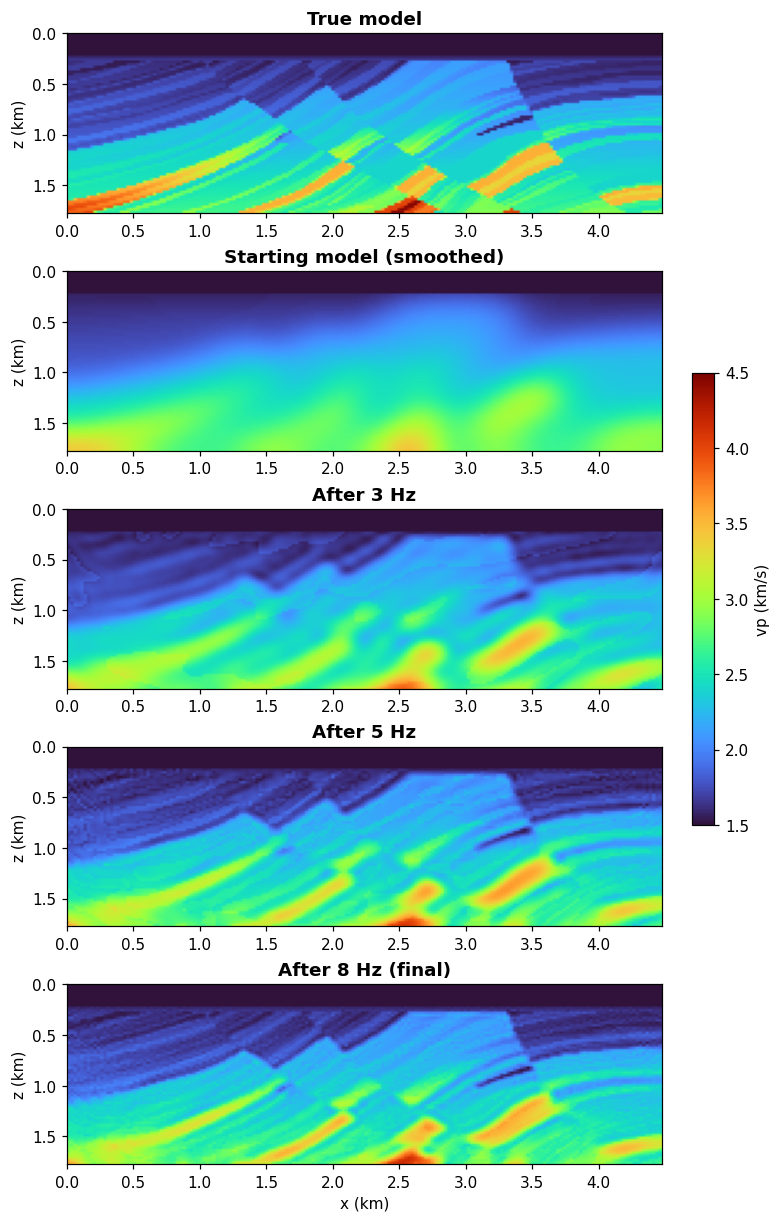

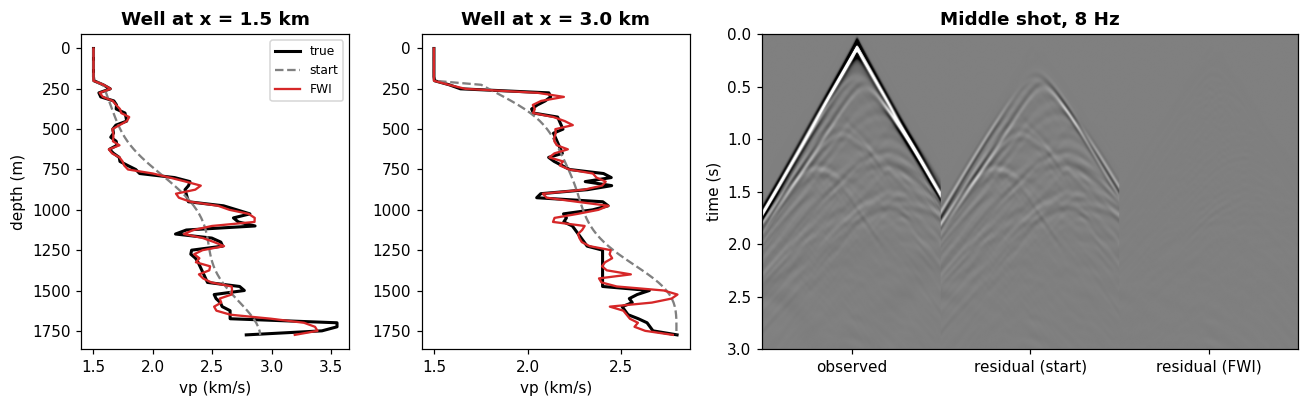

In [8]:
fig, ax = plt.subplots(5, 1, figsize=(7, 11), constrained_layout=True)
for a, (m, t) in zip(ax, [(vt, 'True model'), (v_init, 'Starting model (smoothed)'), (results[3], 'After 3 Hz'), (results[5], 'After 5 Hz'), (results[8], 'After 8 Hz (final)')]):
    im = a.imshow(m.T, cmap='turbo', vmin=1.5, vmax=4.5, extent=ext, aspect='auto'); a.set_title(t); a.set_ylabel('z (km)')
ax[-1].set_xlabel('x (km)'); fig.colorbar(im, ax=ax, shrink=0.4, label='vp (km/s)'); save('ex4_bands'); plt.show()

zz = np.arange(nz) * dx
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw={'width_ratios': [1, 1, 2]})
for a, xw in zip(ax[:2], [1.5, 3.0]):
    i = int(xw * 1000 / dx)
    a.plot(vt[i], zz, 'k', lw=2, label='true'); a.plot(v_init[i], zz, '--', color='gray', label='start'); a.plot(results[8][i], zz, 'C3', label='FWI')
    a.invert_yaxis(); a.set_title(f'Well at x = {xw:.1f} km'); a.set_xlabel('vp (km/s)')
ax[0].set_ylabel('depth (m)'); ax[0].legend(fontsize=8)
fwi8 = FWI(8.0); fwi8.geo.src_positions[0, 0] = src_x[nshots // 2]
d_o = fwi8.dobs[nshots // 2]
model0.update('vp', v_init); d_i = np.array(fwi8.solver.forward(vp=model0.vp)[0].data)
model0.update('vp', results[8]); d_f = np.array(fwi8.solver.forward(vp=model0.vp)[0].data)
c = np.percentile(np.abs(d_o), 98)
ax[2].imshow(np.hstack([d_o, d_o - d_i, d_o - d_f]), aspect='auto', cmap='gray', vmin=-c, vmax=c, extent=[0, 3, T_END/1000, 0])
ax[2].set_xticks([0.5, 1.5, 2.5]); ax[2].set_xticklabels(['observed', 'residual (start)', 'residual (FWI)']); ax[2].set_ylabel('time (s)')
ax[2].set_title('Middle shot, 8 Hz'); plt.tight_layout(); save('ex4_qc'); plt.show()

**Discussion.** The 3 Hz band corrects the long-wavelength velocity; the 5 and 8 Hz bands add the dipping layers, faults and the high-velocity units, consistent with the resolution relation $k = 2f\cos(\theta/2)/v$. Recovery is weaker at depth and near the model edges, where illumination is poor. The data residual drops strongly. Because the observed data were simulated with the same code and without noise (an *inverse crime*, as in the Devito tutorial), field data would need independent checks such as well logs and flat image gathers.

---
## Exercise 5 — Cycle skipping and the misfit landscape

**Goal.** See why FWI needs low frequencies (or a very good starting model).

**Background.** The L2 misfit compares wiggles sample by sample. If a predicted arrival is off by more than half a period, $|\Delta t| > T/2 = 1/(2f)$, the misfit locks onto the wrong cycle and gradient-based optimization converges to a local minimum.

**Tools.** Same Devito forward solver; `model0.update('vp', ...)` to scan models.

**Task.** Scale the true velocity below the water by α ∈ [0.7, 1.3] and compute the misfit of the far-offset traces (offset > 2 km) of one shot at x = 0.1 km, for 3 Hz and 9 Hz Ricker data.

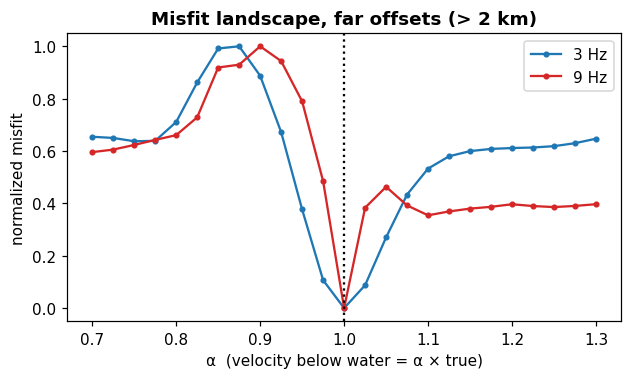

3 Hz: local minima away from alpha = 1 at ['0.750']
9 Hz: local minima away from alpha = 1 at ['1.100', '1.250']


In [9]:
alphas = np.linspace(0.7, 1.3, 25)
xs = 100.; far = np.abs(rec_xy[:, 0] - xs) > 2000.
plt.figure(figsize=(6.5, 3.4)); land = {}
for f0, col in [(3, 'C0'), (9, 'C3')]:
    geo_a = geometry(f0, sx=xs); s_a = AcousticWaveSolver(model, geo_a, space_order=so)
    do = np.array(s_a.forward(vp=model.vp)[0].data); Js = []
    for al in alphas:
        model0.update('vp', np.where(water, 1.5, al * vt).astype(np.float32))
        Js.append(.5 * np.sum(((np.asarray(s_a.forward(vp=model0.vp)[0].data) - do)[:, far])**2))
    Js = np.array(Js) / max(Js); land[f0] = Js
    plt.plot(alphas, Js, 'o-', ms=3, color=col, label=f'{f0} Hz')
plt.axvline(1, color='k', ls=':'); plt.xlabel('α  (velocity below water = α × true)'); plt.ylabel('normalized misfit')
plt.legend(); plt.title('Misfit landscape, far offsets (> 2 km)'); save('ex5_alpha'); plt.show()
for f0, Js in land.items():
    loc = [f'{alphas[i]:.3f}' for i in range(1, len(Js) - 1) if Js[i] < Js[i-1] and Js[i] < Js[i+1] and abs(alphas[i] - 1) > 1e-6]
    print(f'{f0} Hz: local minima away from alpha = 1 at {loc if loc else "none"}')

**Discussion.** At 3 Hz the misfit decreases monotonically towards α = 1 over roughly ±12%: a starting model anywhere in that range converges. At 9 Hz the valley around the true model is only about ±5% wide and a secondary minimum appears next to it; outside the valley the landscape is flat, so the gradient carries no useful information. This is cycle skipping, and it is why practical FWI starts at the lowest usable frequency and moves up (multiscale inversion, Bunks et al., 1995), or uses misfits that measure time shifts rather than sample differences.